In [31]:
# 09 — Station Inventory Estimation
# Reconstruct daily bike inventory at each station from O-D trip counts.
#
# Key idea:
#   net_flow(t) = arrivals(t) - departures(t)
#   inventory(t) = inventory(0) + cumsum(net_flow)
#
# We don't observe inventory(0), but we can infer it:
#   assume the station empties at least once → inventory(0) = -min(cumsum(net_flow))
#   This gives the *minimum-filling* reconstruction: inventory >= 0 everywhere.
#
# From the reconstructed series we can also estimate dock capacity ≈ max(inventory).


In [32]:
## 1. Setup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from dotenv import load_dotenv
from divvy_demand.infra.s3_client import S3Client

load_dotenv('../../.env')
s3 = S3Client(env='prod')


In [33]:
## 2. Load O-D trip data
trip = s3.read_processed('trip/all')
trip['date'] = pd.to_datetime(trip['date'])
trip = trip[trip['date'].dt.year == 2023].copy()
print(f'Trips: {len(trip):,}  |  dates: {trip["date"].min().date()} → {trip["date"].max().date()}')
print(trip.dtypes)


Trips: 2,960,617  |  dates: 2023-01-01 → 2023-12-31
date                  datetime64[ms]
start_station_name               str
start_station_id                 str
end_station_name                 str
end_station_id                   str
total_rides                    int64
member_rides                   int64
casual_rides                   int64
dtype: object


In [34]:
## 3. Daily arrivals, departures, net flow per station
departures = (
    trip.groupby(['start_station_name', 'date'])['total_rides']
    .sum().rename('departures')
)
arrivals = (
    trip.groupby(['end_station_name', 'date'])['total_rides']
    .sum().rename('arrivals')
    .rename_axis(index={'end_station_name': 'start_station_name'})
)

flow = (
    pd.concat([departures, arrivals], axis=1)
    .fillna(0)
    .assign(net_flow=lambda d: d['arrivals'] - d['departures'])
    .reset_index()
)

# Pivot to (station x date) matrices
all_dates   = pd.date_range(trip['date'].min(), trip['date'].max())
all_stations = sorted(flow['start_station_name'].unique())

net_pivot = (
    flow.pivot(index='start_station_name', columns='date', values='net_flow')
    .reindex(columns=all_dates, fill_value=0)
    .fillna(0)
)
print(f'Net-flow matrix: {net_pivot.shape}  (stations x days)')


Net-flow matrix: (1588, 365)  (stations x days)


Capacity estimates (top 10):
start_station_name
DuSable Lake Shore Dr & North Blvd    4285.0
Columbus Dr & Randolph St             3400.0
Sheffield Ave & Waveland Ave          3290.0
Desplaines St & Kinzie St             3068.0
Green St & Randolph St*               2917.0
Sedgwick St & Huron St                2626.0
Wells St & Walton St                  2398.0
Financial Pl & Ida B Wells Dr         2334.0
Streeter Dr & Grand Ave               2186.0
Michigan Ave & 8th St                 2146.0

Median estimated capacity: 15.0 docks
Mean   estimated capacity: 150.0 docks


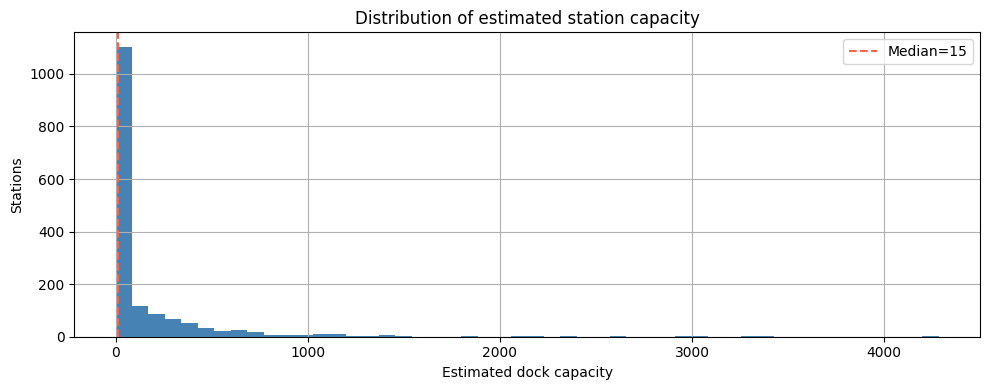

In [35]:
## 4. Reconstruct inventory (minimum-filling method)
# cumsum across time axis → relative inventory change
cumflow = net_pivot.cumsum(axis=1)

# Shift so minimum is 0 (station hit empty at least once)
init_inv = (-cumflow.min(axis=1)).clip(lower=0)  # inventory(0) per station
inventory = cumflow.add(init_inv, axis=0)        # absolute inventory

# Capacity estimate: max inventory observed + small buffer
capacity = inventory.max(axis=1).rename('capacity_est')

print(f'Capacity estimates (top 10):')
print(capacity.sort_values(ascending=False).head(10).to_string())
print(f'\nMedian estimated capacity: {capacity.median():.1f} docks')
print(f'Mean   estimated capacity: {capacity.mean():.1f} docks')

fig, ax = plt.subplots(figsize=(10, 4))
capacity.hist(bins=50, ax=ax, color='steelblue', edgecolor='none')
ax.axvline(capacity.median(), color='tomato', linestyle='--', label=f'Median={capacity.median():.0f}')
ax.set_xlabel('Estimated dock capacity'); ax.set_ylabel('Stations')
ax.set_title('Distribution of estimated station capacity')
ax.legend(); plt.tight_layout(); plt.show()


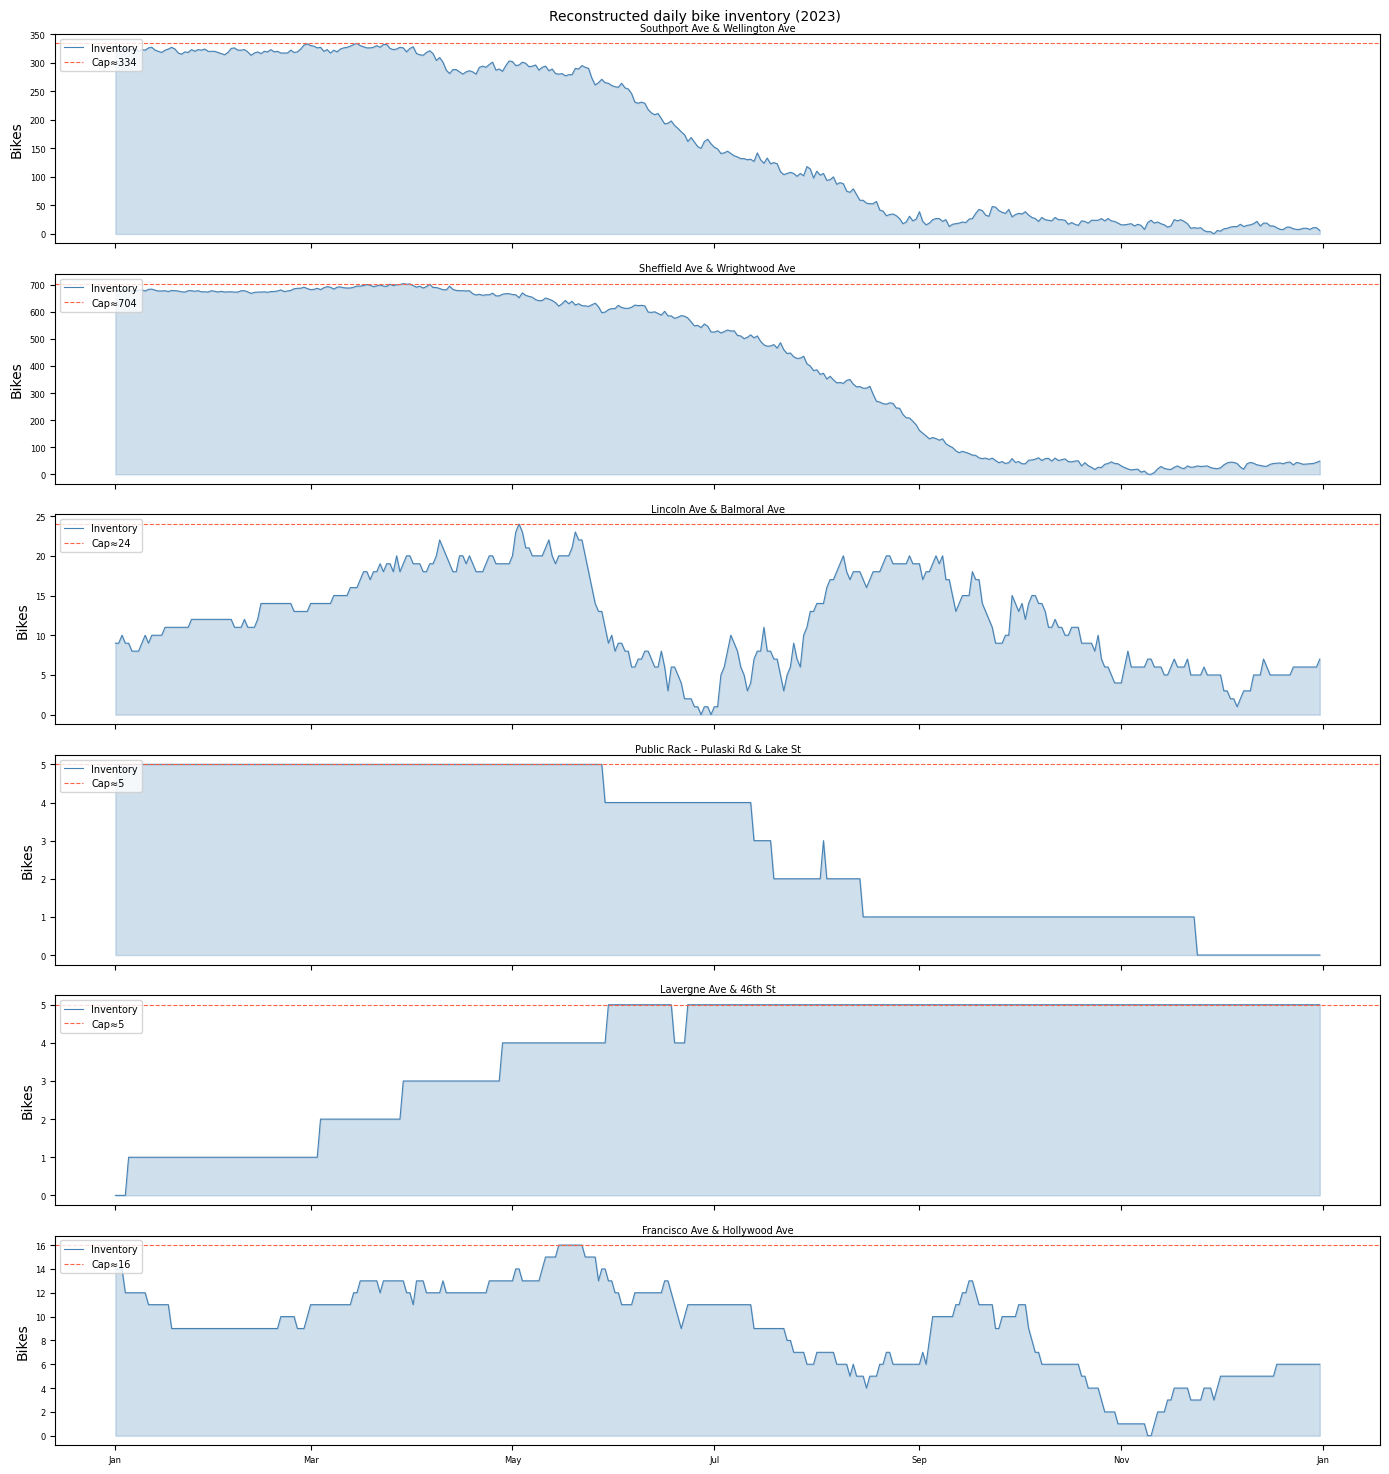

In [36]:
## 5. Inventory time-series — sample stations
K_SAMPLES = 6
np.random.seed(0)
# Pick from active stations (capacity >= 5 docks)
active_stns = capacity[capacity >= 5].index.tolist()
sample_stns = np.random.choice(active_stns, K_SAMPLES, replace=False)

fig, axes = plt.subplots(K_SAMPLES, 1, figsize=(14, 2.5 * K_SAMPLES), sharex=True)
for ax, stn in zip(axes, sample_stns):
    inv  = inventory.loc[stn]
    cap  = capacity.loc[stn]
    ax.fill_between(all_dates, inv.values, alpha=0.25, color='steelblue')
    ax.plot(all_dates, inv.values, color='steelblue', linewidth=0.8, label='Inventory')
    ax.axhline(cap, color='tomato', linewidth=0.8, linestyle='--', label=f'Cap≈{cap:.0f}')
    ax.set_ylabel('Bikes'); ax.legend(fontsize=7, loc='upper left')
    ax.set_title(stn[:60], fontsize=7, pad=2)
    ax.tick_params(labelsize=6)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%b'))
fig.suptitle('Reconstructed daily bike inventory (2023)', fontsize=10)
plt.tight_layout(); plt.show()


Found 41 lakeshore stations:
  Ashland Ave & Lake St  (cap≈1128)
  Austin Blvd & Lake St  (cap≈18)
  California Ave & Lake St  (cap≈304)
  Central Ave & Lake St  (cap≈28)
  Cicero Ave & Lake St  (cap≈13)
  Clark St & Lake St  (cap≈321)
  Clinton St & Lake St  (cap≈626)
  Conservatory Dr & Lake St  (cap≈68)
  Damen Ave & Walnut (Lake) St  (cap≈188)
  DuSable Lake Shore Dr & Belmont Ave  (cap≈635)
  DuSable Lake Shore Dr & Diversey Pkwy  (cap≈719)
  DuSable Lake Shore Dr & Monroe St  (cap≈1819)
  DuSable Lake Shore Dr & North Blvd  (cap≈4285)
  DuSable Lake Shore Dr & Wellington Ave  (cap≈612)
  Eastlake Ter & Howard St  (cap≈111)
  Franklin St & Lake St  (cap≈567)
  Kedzie Ave & Lake St  (cap≈63)
  Kostner Ave & Lake St  (cap≈35)
  Lake Park Ave & 35th St  (cap≈88)
  Lake Park Ave & 47th St  (cap≈465)
  Lake Park Ave & 53rd St  (cap≈435)
  Lake Park Ave & 56th St  (cap≈376)
  Lakefront Trail & Bryn Mawr Ave  (cap≈433)
  Lakefront Trail & Wilson Ave  (cap≈338)
  Lakeview Ave & Fullerton 



In [37]:
## Lakeshore stations — inventory time series
lakeshore_stns = [s for s in inventory.index if 'lake' in s.lower()]
print(f'Found {len(lakeshore_stns)} lakeshore stations:')
for s in sorted(lakeshore_stns):
    print(f'  {s}  (cap≈{capacity.loc[s]:.0f})')

fig, axes = plt.subplots(len(lakeshore_stns), 1,
                         figsize=(14, 2.5 * len(lakeshore_stns)),
                         sharex=True)
if len(lakeshore_stns) == 1:
    axes = [axes]

for ax, stn in zip(axes, sorted(lakeshore_stns)):
    inv = inventory.loc[stn]
    cap = capacity.loc[stn]
    ax.fill_between(all_dates, inv.values, alpha=0.25, color='steelblue')
    ax.plot(all_dates, inv.values, color='steelblue', linewidth=0.8, label='Inventory')
    ax.axhline(cap, color='tomato', linewidth=0.8, linestyle='--', label=f'Cap≈{cap:.0f}')
    ax.set_ylabel('Bikes', fontsize=7)
    ax.legend(fontsize=7, loc='upper left')
    ax.set_title(stn, fontsize=8, pad=2)
    ax.tick_params(labelsize=6)

axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%b'))
fig.suptitle('Lakeshore stations — reconstructed daily inventory (2023)', fontsize=10)
plt.tight_layout(); plt.show()


Matched stations:
  Dusable Harbor  (cap≈927)
  Streeter Dr & Grand Ave  (cap≈2186)
  Streeter Dr/Grand Ave  (cap≈13)


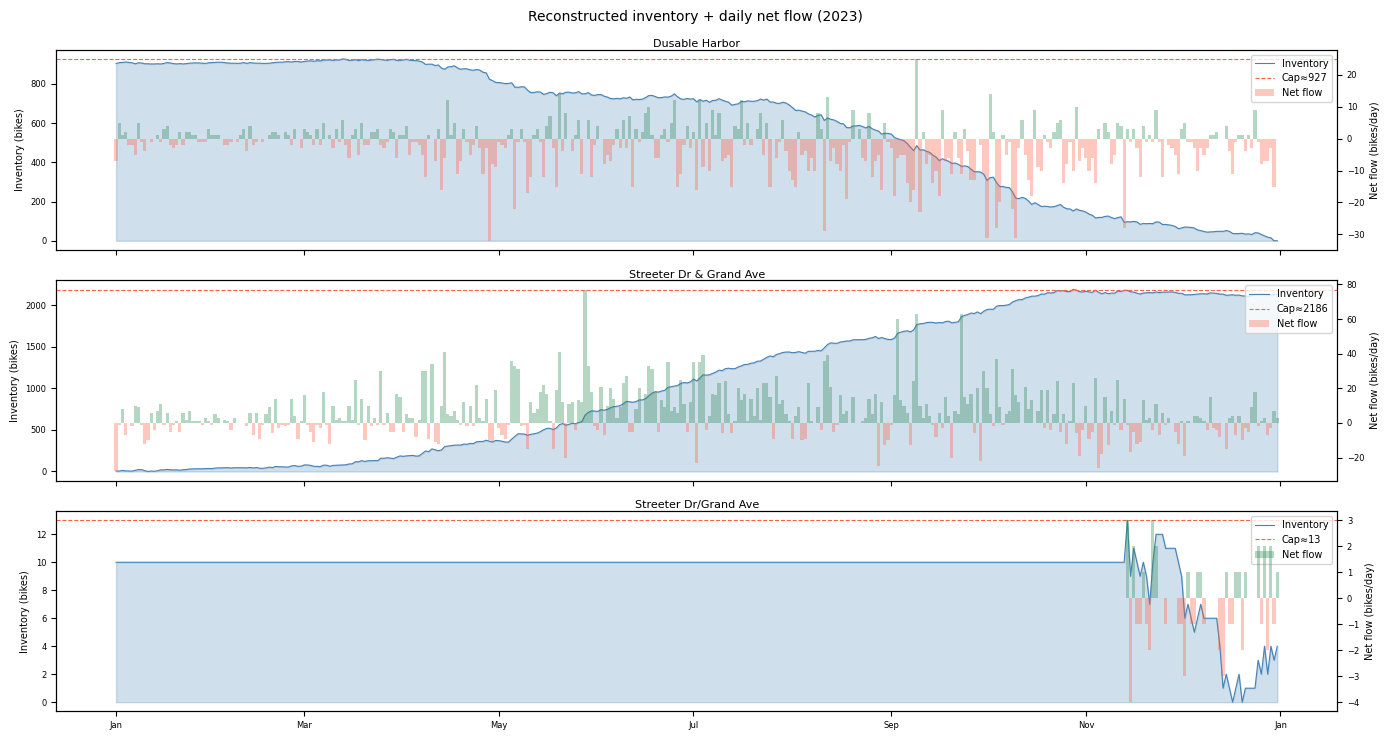

In [38]:
## Streeter Dr & Grand Ave + DuSable Harbor
keywords = ['streeter', 'dusable harbor']
target_stns = [
    s for s in inventory.index
    if any(kw in s.lower() for kw in keywords)
]
print('Matched stations:')
for s in target_stns:
    print(f'  {s}  (cap≈{capacity.loc[s]:.0f})')

fig, axes = plt.subplots(len(target_stns), 1,
                         figsize=(14, 2.5 * len(target_stns)),
                         sharex=True)
if len(target_stns) == 1:
    axes = [axes]

for ax, stn in zip(axes, target_stns):
    inv = inventory.loc[stn]
    cap = capacity.loc[stn]
    dep = net_pivot.loc[stn].clip(upper=0).abs()  # departures in excess of arrivals
    ax.fill_between(all_dates, inv.values, alpha=0.25, color='steelblue')
    ax.plot(all_dates, inv.values, color='steelblue', linewidth=0.8, label='Inventory')
    ax.axhline(cap, color='tomato', linewidth=0.8, linestyle='--', label=f'Cap≈{cap:.0f}')
    ax2 = ax.twinx()
    ax2.bar(all_dates, net_pivot.loc[stn].values,
            color=np.where(net_pivot.loc[stn].values >= 0, 'seagreen', 'tomato'),
            alpha=0.35, width=1, label='Net flow')
    ax2.set_ylabel('Net flow (bikes/day)', fontsize=7)
    ax2.tick_params(labelsize=6)
    ax.set_ylabel('Inventory (bikes)', fontsize=7)
    ax.set_title(stn, fontsize=8, pad=2)
    ax.tick_params(labelsize=6)
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2, fontsize=7, loc='upper right')

axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%b'))
fig.suptitle('Reconstructed inventory + daily net flow (2023)', fontsize=10)
plt.tight_layout(); plt.show()


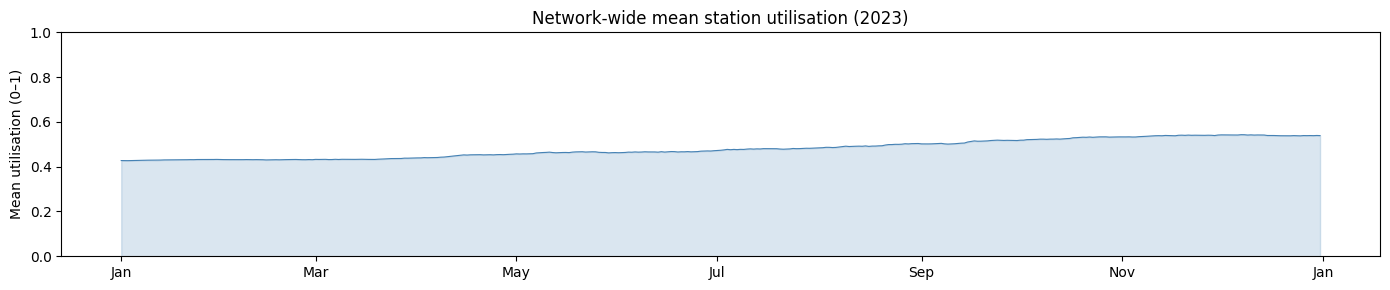

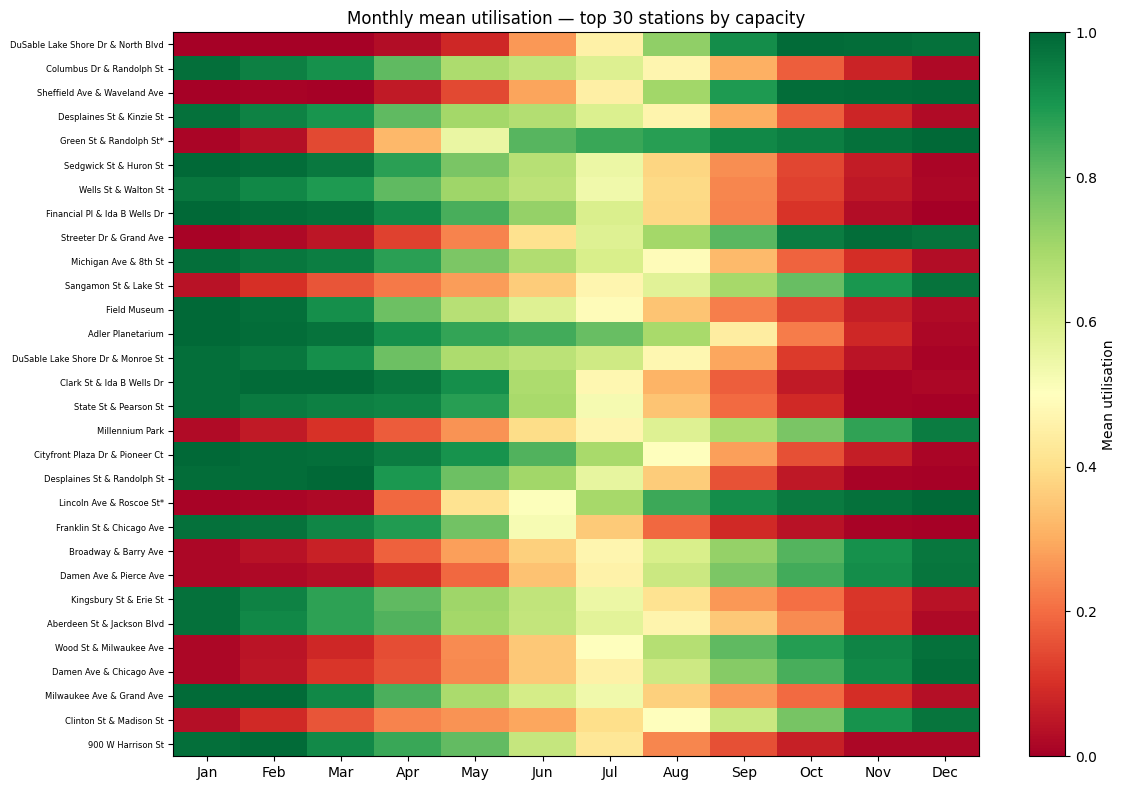

In [39]:
## 6. Utilisation: inventory / capacity
utilisation = inventory.div(capacity.replace(0, np.nan), axis=0).clip(0, 1)

# Mean daily utilisation across all stations
mean_util = utilisation.mean(axis=0)

fig, ax = plt.subplots(figsize=(14, 3))
ax.plot(all_dates, mean_util.values, color='steelblue', linewidth=0.8)
ax.fill_between(all_dates, mean_util.values, alpha=0.2, color='steelblue')
ax.set_ylabel('Mean utilisation (0–1)')
ax.set_title('Network-wide mean station utilisation (2023)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.set_ylim(0, 1); plt.tight_layout(); plt.show()

# Heatmap: top 30 busiest stations x month
top30 = capacity.sort_values(ascending=False).head(30).index
util_monthly = (
    utilisation.loc[top30]
    .T.resample('ME').mean().T
)
util_monthly.columns = util_monthly.columns.strftime('%b')

fig, ax = plt.subplots(figsize=(12, 8))
im = ax.imshow(util_monthly.values, aspect='auto', cmap='RdYlGn', vmin=0, vmax=1)
ax.set_xticks(range(len(util_monthly.columns))); ax.set_xticklabels(util_monthly.columns)
ax.set_yticks(range(len(top30))); ax.set_yticklabels([s[:40] for s in top30], fontsize=6)
plt.colorbar(im, ax=ax, label='Mean utilisation')
ax.set_title('Monthly mean utilisation — top 30 stations by capacity')
plt.tight_layout(); plt.show()


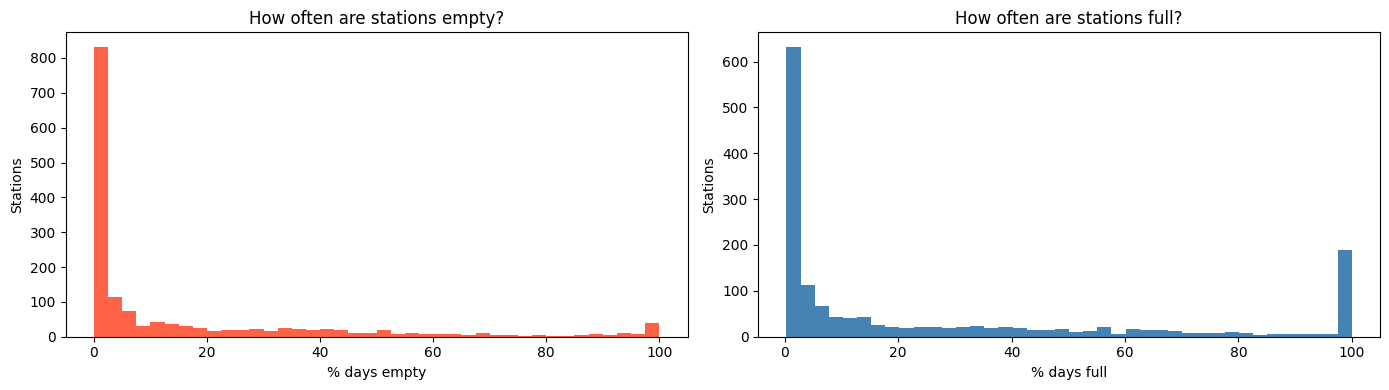

Most-empty stations:
                                          capacity  empty_days  empty_pct
start_station_name                                                       
Public Rack - Devon Ave & Kinzua Ave           0.0         365      100.0
Public Rack - May St & 78th St                 0.0         365      100.0
Public Rack - St Louis & 83rd                  0.0         365      100.0
Public Rack - 53rd St & Indiana Ave            0.0         365      100.0
Public Rack - South Shore High School          0.0         365      100.0
Public Rack - Racine Ave & 83rd St             0.0         365      100.0
Public Rack - Albany Ave & 111th St - NW       0.0         365      100.0
Public Rack - Northwest Hwy & Raven St         0.0         365      100.0
Public Rack - Normal Blvd & 61st Pl            0.0         365      100.0
Public Rack - New England Ave & Grace St       0.0         365      100.0

Most-full stations:
                                                  capacity  full_days 

In [40]:
## 7. Empty and full-station events
# Empty: inventory == 0
# Full:  inventory >= capacity (within 1 bike tolerance)
empty_days = (inventory == 0).sum(axis=1).rename('empty_days')
full_days  = (inventory >= capacity.sub(1).clip(lower=0), ).pop() if False else \
             inventory.ge(capacity.sub(1).clip(lower=0), axis=0).sum(axis=1).rename('full_days')

event_df = pd.DataFrame({'capacity': capacity, 'empty_days': empty_days, 'full_days': full_days})
event_df['empty_pct'] = event_df['empty_days'] / len(all_dates) * 100
event_df['full_pct']  = event_df['full_days']  / len(all_dates) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(event_df['empty_pct'], bins=40, color='tomato',   edgecolor='none')
axes[0].set_xlabel('% days empty'); axes[0].set_ylabel('Stations')
axes[0].set_title('How often are stations empty?')
axes[1].hist(event_df['full_pct'],  bins=40, color='steelblue', edgecolor='none')
axes[1].set_xlabel('% days full');  axes[1].set_ylabel('Stations')
axes[1].set_title('How often are stations full?')
plt.tight_layout(); plt.show()

print('Most-empty stations:')
print(event_df.sort_values('empty_pct', ascending=False).head(10)[['capacity','empty_days','empty_pct']].to_string())
print('\nMost-full stations:')
print(event_df.sort_values('full_pct', ascending=False).head(10)[['capacity','full_days','full_pct']].to_string())


In [41]:
## 8. Map: capacity and mean utilisation
import folium
from branca.colormap import linear

# Fetch coords
raw_frames = []
for month in [3, 6, 9]:
    raw = s3.read_raw(2023, month)
    raw_frames.append(raw[['start_station_name', 'start_lat', 'start_lng']].dropna())
station_coords = (
    pd.concat(raw_frames, ignore_index=True)
    .groupby('start_station_name')[['start_lat', 'start_lng']].mean()
    .reset_index()
)

mean_util_stn = utilisation.mean(axis=1).rename('mean_util')
map_df = (
    pd.DataFrame({'capacity': capacity, 'mean_util': mean_util_stn})
    .reset_index()
    .rename(columns={'index': 'start_station_name',
                     'start_station_name': 'start_station_name'})
    .merge(station_coords, on='start_station_name', how='left')
    .dropna(subset=['start_lat', 'start_lng'])
)
print(f'Stations on map: {len(map_df)}')

cmap = linear.RdYlGn_09.scale(0, 1)
cmap.caption = 'Mean utilisation'

m = folium.Map(location=[41.8781, -87.6298], zoom_start=11, tiles='OpenStreetMap')
for _, row in map_df.iterrows():
    folium.CircleMarker(
        location=[row['start_lat'], row['start_lng']],
        radius=max(3, row['capacity'] / 6),  # size = capacity
        color=cmap(row['mean_util']),
        fill=True, fill_color=cmap(row['mean_util']), fill_opacity=0.75, weight=1,
        popup=folium.Popup(
            f"<b>{row['start_station_name']}</b><br>"
            f"Cap≈{row['capacity']:.0f}  util={row['mean_util']:.2f}",
            max_width=260
        ),
        tooltip=row['start_station_name'],
    ).add_to(m)
cmap.add_to(m)

m.save('inventory_map.html')
print('Saved to inventory_map.html')
m


Stations on map: 1423


ValueError: Thresholds are not sorted.